# YZM 411 — Yelek tespiti ve sınıflandırması (klasik yöntemler)
Çalışan defter (10a): baştan sona, **dondurulmuş** `params.json` ve `gt.json` ile bütün sonuçları yeniden üretir.
Bu defter sunum değildir; slaytlar ve sonuç tablosu Drive'daki proje klasöründe ayrıca durur.

Sıra: veri ve kutular (A) → renk (B) → kenar ve şablon (C) → öznitelik (D) → tek değişkenli deneyler → sonuç tablosu (E).
`results/` dosyalarının üzerine yazdığı için bu defteri **aynı anda tek kişi** çalıştırsın (E).

> Colab: defteri Drive'da açın (çift tık → *Birlikte aç → Google Colaboratory*). İlk hücre Drive'ı bağlar ve proje klasörünü kendisi bulur. Defterde yaptığınız değişiklik doğrudan Drive'daki dosyaya kaydedilir; *Drive'a kopya kaydet* **kullanmayın** (kopya "Colab Notebooks" klasörüne gider, grup göremez).

In [1]:
# --- Kurulum: Google Drive'ı bağlar ve proje klasörünü bulur (GitHub gerekmez) ---
PROJE = ''   # boş bırakın, otomatik bulunur; bulunamazsa Drive'daki yolu yazın: '/content/drive/MyDrive/.../yelek-tespiti'
import os, sys, glob, unicodedata
sys.dont_write_bytecode = True                      # Drive'daki src/ klasörüne __pycache__ yazılmasın

def _proje_mi(p):
    return os.path.isfile(os.path.join(p, 'src', 'common.py')) and os.path.isfile(os.path.join(p, 'config', 'params.json'))

if 'google.colab' in sys.modules:
    from google.colab import drive
    drive.mount('/content/drive')
    PROJE = PROJE.strip().rstrip('/')
    if PROJE and not _proje_mi(PROJE):               # Türkçe harf kodlaması farkı (ör. 'Ödevler')
        PROJE = next((unicodedata.normalize(f, PROJE) for f in ('NFC', 'NFD')
                      if _proje_mi(unicodedata.normalize(f, PROJE))), PROJE)
    if not PROJE:                                    # Drive'ım ve ortak drive'larda 4 klasör derinliğe kadar ara
        for d in range(5):
            bulunan = sorted({os.path.dirname(os.path.dirname(p))
                              for k in ('/content/drive/MyDrive', '/content/drive/Shareddrives')
                              for p in glob.glob(os.path.join(k, *['*'] * d, 'src', 'common.py'))})
            bulunan = [p for p in bulunan if _proje_mi(p)]
            if bulunan:
                PROJE = bulunan[0]
                if len(bulunan) > 1:
                    print('Birden fazla proje klasörü bulundu, ilki kullanılıyor:', *bulunan, sep='\n  ')
                break
    if not PROJE or not _proje_mi(PROJE):
        raise FileNotFoundError("Proje klasörü bulunamadı. Drive'da paylaşılan 'yelek-tespiti' klasörüne sağ tık -> "
                                "Düzenle -> Kısayol ekle -> Drive'ım; sonra bu hücreyi yeniden çalıştırın "
                                "(ya da yukarıda PROJE = '/content/drive/MyDrive/...' yazın).")
    os.chdir(PROJE)
elif os.path.basename(os.getcwd()) == 'notebooks':  # Colab dışında (Jupyter / VS Code)
    os.chdir('..')
sys.path.insert(0, os.path.join(os.getcwd(), 'src'))
try:                                                # Colab'ın Python 3.13 sürümünde autoreload bozuk; varsa açılır, yoksa geçilir
    get_ipython().run_line_magic('reload_ext', 'autoreload'); get_ipython().run_line_magic('autoreload', '2')
except Exception:
    pass
import warnings; warnings.filterwarnings('ignore')
%matplotlib inline
%config InlineBackend.figure_format = 'jpeg'   # defter boyutu küçük kalsın
from common import *
gt, P = load_gt(), load_params()
durum()

Mounted at /content/drive
Proje klasörü : /content/drive/MyDrive/Yelek tespit deneme/yelek-tespiti-drive/yelek-tespiti
Görüntüler    : 20/20 hazır (data/images_1024)
gt.json       : 20 görüntü, 20 tanesinde kutu var
params dondu mu: True 2026-11-10T21:09:21
Kayıtlar      : 1 dosya kaydı, son: dondurma-2 (2026-11-10T21:09:21)


In [2]:
assert P['_frozen'], ("params.json dondurulmadan main.ipynb çalıştırılmaz (5e): "
                      "B, B_renk.ipynb'deki Dondurma 2 hücresini çalıştırmalı")
validate_gt(gt)
kayit_kontrol()          # tahminler (4a) ve dondurma kayıtları; "DEĞİŞTİ" görmemelisiniz

gt.json kontrolü: sorun yok


,zaman,etiket,dosya,su_an
0,2026-11-10T21:09:21,dondurma-2,config/params.json,aynı


## 5 — Renk yöntemi

Doğru sınıf: 8/12 | TP/FP/FN (12 görüntü): 4/92/4


kural,Yelek giyili,"Yelek var, giyili değil",Yelek yok,Belirsiz
doğru,,,,
Yelek giyili,4,0,2,0
"Yelek var, giyili değil",0,1,1,0
Yelek yok,1,0,3,0
Belirsiz,0,0,0,0


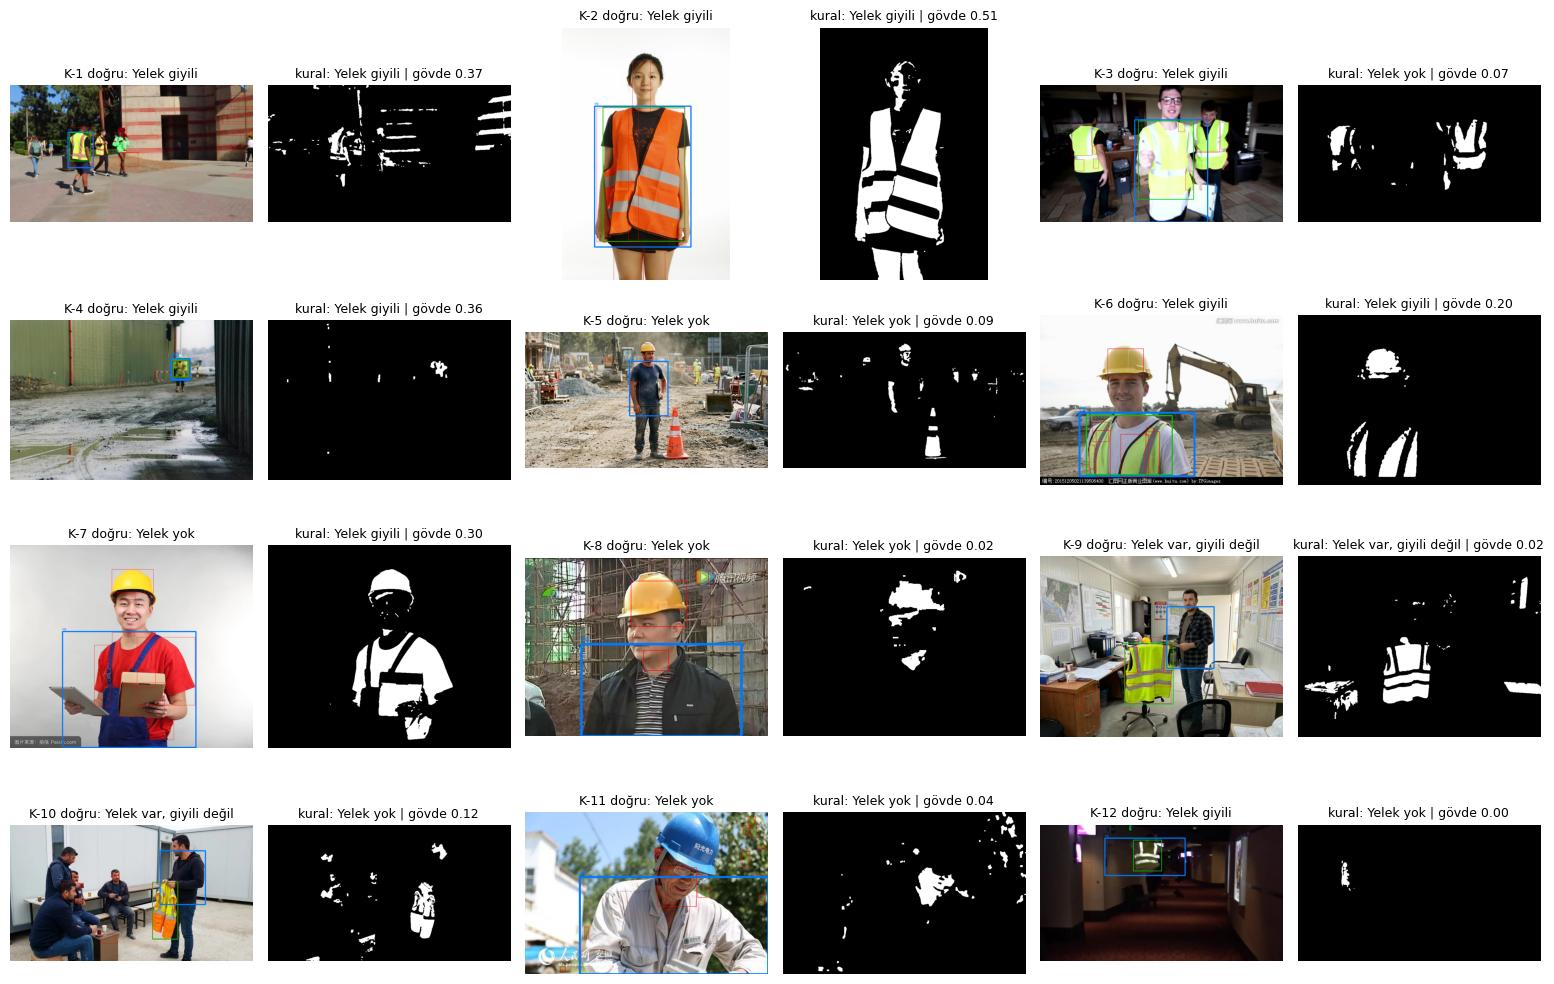

In [3]:
import color
col = color.run(CTRL_IDS, gt, P)
color.summary(col)
display(color.confusion(col))
color.show_masks(CTRL_IDS, gt, P, path=RES / 'fig' / 'masks_control.png');

## 6 — Kenar ve şablon

canny_orani               gy_gx              
            count   mean median count   mean median
yelek                                              
False           6  0.127  0.141     6  0.942  0.842
True            6  0.103  0.075     6  0.797  0.750

,seri,deger,skor,uzaklik_px,dolgu_orani
0,referans,"0° / 1,0",1.000000,0.000000,0.000000
1,döndürme,10°,0.628590,4.123106,0.073462
2,döndürme,20°,0.641203,81.412530,0.123661
3,döndürme,30°,0.583389,83.862983,0.154678
4,ölçek,0.9,0.939766,3.162278,0.000000
5,ölçek,0.8,0.879747,8.602325,0.000000
6,ölçek,0.7,0.810751,14.212670,0.000000


,count,mean,median,max
yelek,,,,
False,6,0.357,0.389,0.469
True,6,0.531,0.549,0.617


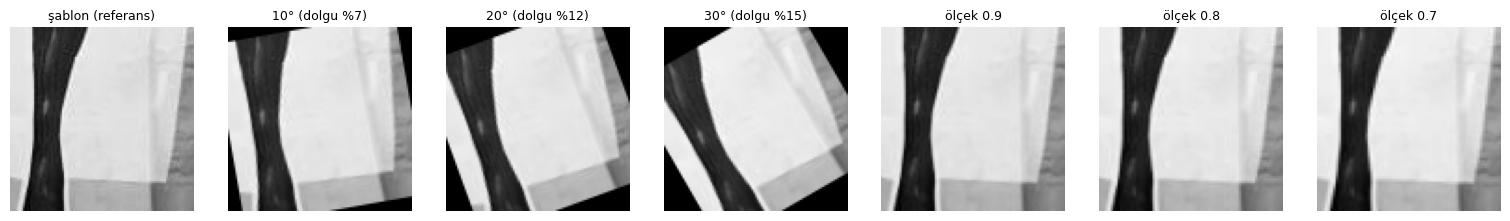

In [4]:
import edge, template
ed = edge.run(DEV_IDS + CTRL_IDS, gt, P)
display(edge.side_by_side(ed[ed.ayirim == 'kontrol']))
display(template.series(P, gt))
tc = template.control_scores(CTRL_IDS, gt, P)
template.side_by_side(tc)

## 7 — Öznitelik

{'oran_testi': 0.75,
 'ransac_px': 3.0,
 'model': 'homography',
 'kp_A': 188,
 'kp_B': 141,
 'gecen_eslesme': 73,
 'ic_deger': 64,
 'kose_hatasi_px': 0.4819289445877075,
 'kose_hatalari_px': [0.26, 0.33, 0.27, 1.07]}

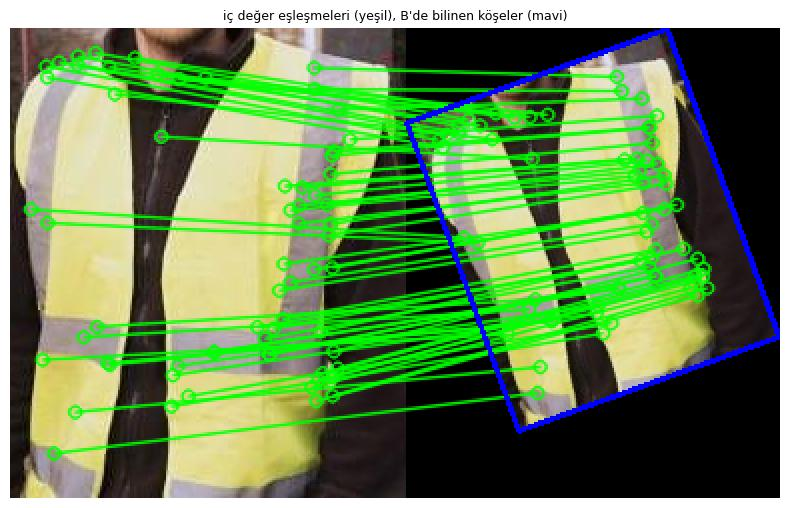

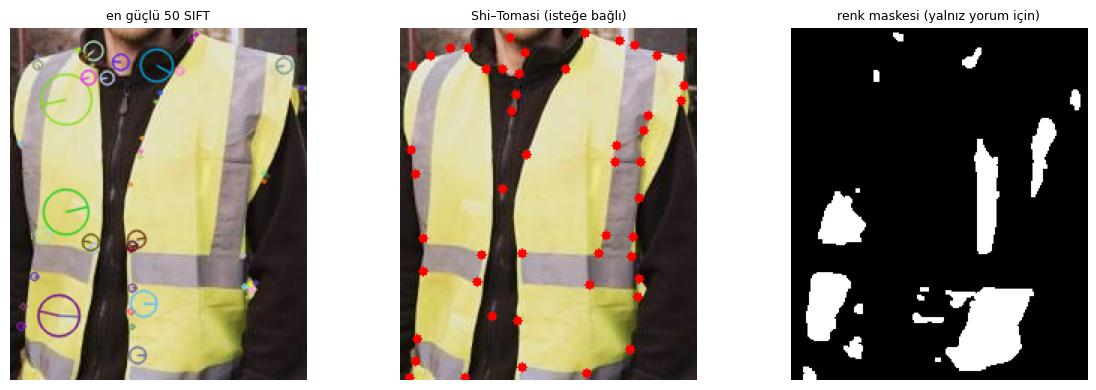

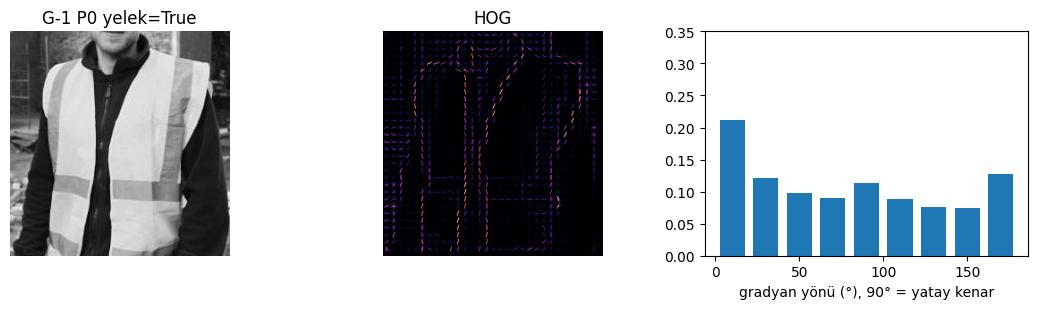

In [5]:
import features
res, pair = features.run_all(P, gt, hog_items=[(P['features']['dev_id'], 0)])
res['7a']

## Tek değişkenli deneyler (D1, D2, D4, D6, D8)

In [6]:
import experiments
d1 = experiments.d1(CTRL_IDS, gt, P, kisi='A')
d2 = experiments.d2(CTRL_IDS, gt, P, kisi='B')
d4 = experiments.d4(CTRL_IDS, gt, P, kisi='C')
d6 = experiments.d6(P, gt, kisi='D')
d8 = experiments.d8(CTRL_IDS, gt, P, kisi='E')
print('kaydedildi: results/d1_kucultme.csv, d2_filtre.csv, d4_canny.csv, d6_eslestirme.csv, d8_difuzyon.csv')

kaydedildi: results/d1_kucultme.csv, d2_filtre.csv, d4_canny.csv, d6_eslestirme.csv, d8_difuzyon.csv


## 10b — Sonuç tablosu

In [7]:
import merge
final = merge.build()
final

Doğru sınıf: 8/12


,Görüntü,Koşul,Doğru sınıf,Kuralın sınıfı,Gövde maske oranı,Şerit kanıtı (Canny kenar oranı / şablon skoru),TP / FP / FN
0,K-1,normal ışık; sarı yelek,Yelek giyili,Yelek giyili,"%36,7","0,11 / 0,57",1 / 15 / 0
1,K-2,normal ışık; turuncu yelek,Yelek giyili,Yelek giyili,"%50,9","0,04 / 0,53",1 / 5 / 0
2,K-3,gölge / iç mekân düşük ışık; yelekli,Yelek giyili,Yelek yok,"%6,8","0,04 / 0,49",0 / 10 / 1
3,K-4,"uzak, küçük işçi (gövde 42 px); yelekli",Yelek giyili,Yelek giyili,"%35,6","0,30 / 0,61",1 / 0 / 0
4,K-5,koni; yeleksiz işçi (9a hata incelemesi adayı),Yelek yok,Yelek yok,"%8,6","0,15 / 0,47",0 / 13 / 0
5,K-6,sarı iş makinesi (ekskavatör); yelekli,Yelek giyili,Yelek giyili,"%19,6","0,11 / 0,62",0 / 7 / 1
6,K-7,"yeleksiz; kırmızı tişört + mavi tulum, şerit yok",Yelek yok,Yelek giyili,"%29,7","0,03 / 0,41",0 / 8 / 0
7,K-8,yeleksiz; sarı baret (yelek renginde nesne),Yelek yok,Yelek yok,"%1,7","0,14 / 0,36",0 / 3 / 0
8,K-9,giyili değil: sandalyede yelek; yeleksiz kişi,"Yelek var, giyili değil","Yelek var, giyili değil","%2,5","0,20 / 0,24",0 / 10 / 1
9,K-10,giyili değil: elde tutulan yelek,"Yelek var, giyili değil",Yelek yok,"%12,5","0,11 / 0,22",1 / 9 / 0


In [8]:
deney_kayitlari()        # herkesin results/experiments_<kişi>.csv dosyası -> results/experiments.csv (4b)

,zaman,deney,kisi,girdi,parametre,cikti,yorum
0,2026-11-10T21:01:27,D1 küçültme oranı,A,"G-1,G-2,G-3,G-4,G-5,G-6,G-7,G-8","{""ratios"": [1, 0.5, 0.25, 0.125], ""nearest_rat...","{""govde_maske_orani"": {""0.125→1 geri büyütme (...",YORUM: notta yazılacak
1,2026-11-10T21:02:24,D1 küçültme oranı,A,"G-1,G-2,G-3,G-4,G-5,G-6,G-7,G-8","{""ratios"": [1, 0.5, 0.25, 0.125], ""nearest_rat...","{""govde_maske_orani"": {""0.125→1 geri büyütme (...",YORUM: notta yazılacak
2,2026-11-10T21:10:20,D2 filtre türü,B,"K-1,K-2,K-3,K-4,K-5,K-6,K-7,K-8,K-9,K-10,K-11,...","{""filters"": [{""name"": ""none""}, {""name"": ""gauss...","{""govde_maske_orani"": {""bilateral"": 0.173, ""ga...",YORUM: notta yazılacak
3,2026-11-10T21:19:35,D4 Canny eşikleri,C,"K-1,K-2,K-3,K-4,K-5,K-6,K-7,K-8,K-9,K-10,K-11,...","{""pairs"": [[20, 60], [50, 150], [100, 250]]}","{""100/250 yelek=False"": 0.077, ""100/250 yelek=...",YORUM: notta yazılacak
4,2026-11-10T21:20:58,D6 eşleştirme eşiği,D,G-1,"{""mode"": ""ratio"", ""ratios"": [0.6, 0.75, 0.9], ...","[{""oran_testi"": 0.6, ""ransac_px"": 3.0, ""gecen_...",YORUM: notta yazılacak
5,2026-11-10T21:25:08,D8 difüzyon süresi,E,"K-1,K-2,K-3,K-4,K-5,K-6,K-7,K-8,K-9,K-10,K-11,...","{""steps"": [0, 10, 40], ""dt"": 0.2, ""gauss_sigma...","{""govde_maske_orani"": {""Gauss σ=4"": 0.176, ""di...",YORUM: notta yazılacak
6,2026-11-10T21:33:50,D1 küçültme oranı,A,"K-1,K-2,K-3,K-4,K-5,K-6,K-7,K-8,K-9,K-10,K-11,...","{""ratios"": [1, 0.5, 0.25, 0.125], ""nearest_rat...","{""govde_maske_orani"": {""0.125→1 geri büyütme (...",YORUM: notta yazılacak
7,2026-11-10T21:56:54,D1 küçültme oranı,A,"K-1,K-2,K-3,K-4,K-5,K-6,K-7,K-8,K-9,K-10,K-11,...","{""ratios"": [1, 0.5, 0.25, 0.125], ""nearest_rat...","{""govde_maske_orani"": {""0.125→1 geri büyütme (...",YORUM: notta yazılacak
8,2026-11-10T21:56:55,D1 küçültme oranı,A,"G-1,G-2,G-3,G-4,G-5,G-6,G-7,G-8","{""ratios"": [1, 0.5, 0.25, 0.125], ""nearest_rat...","{""govde_maske_orani"": {""0.125→1 geri büyütme (...",YORUM: notta yazılacak
9,2026-11-10T21:58:35,D2 filtre türü,B,"K-1,K-2,K-3,K-4,K-5,K-6,K-7,K-8,K-9,K-10,K-11,...","{""filters"": [{""name"": ""none""}, {""name"": ""gauss...","{""govde_maske_orani"": {""bilateral"": 0.173, ""ga...",YORUM: notta yazılacak


**Bitirirken (isteğe bağlı):** Colab, Drive'a yazmayı arka planda bitirir. Oturumu hemen kapatacaksanız aşağıdaki hücre
bekleyen yazmaları tamamlar (Drive bağlantısını da keser).

In [9]:
# drive_kaydet()